# 10 Sensitivity of the slip model: supplementary figures and table

```
Author: Danielle Lindsay
Environment: environment.yml. Runs after 07, 09 and the scripts in scripts/sensitivity/. Seconds; no inversion is run here.
```

**What this notebook does**

1. Reads the stored results of the sensitivity scripts (`scripts/sensitivity/*.py`, whose csv files are archived on
   Zenodo) and of notebooks 07 and 09, and lists the script that wrote each csv (section 2).
2. Writes the sensitivity table and checks its baseline row against the preferred model of notebook 09 (section 3).
3. Draws the sweeps figure: fault dip, regularisation strength $\sigma$ and prior lengths $\lambda$ (section 4).
4. Draws the fixed-depth scan, with its noise test, the buried-top test and the SFSVM basement depth (section 5).
5. Draws the error of the PyLith Green's functions against the analytic solution (section 6).
6. Draws the semivariogram of the noise model (section 7).
7. Shows how the west-east asymmetry of the near-fault deflection depends on the no-fault-normal assumption of the
   decomposition, and whether the decomposition makes the asymmetry of the preferred model (section 8,
   `scripts/sensitivity/fault_normal_leak.py`, `forward_decomposition_check.py`).

**Inputs** (`model_config.sensitivity_dir`): `sensitivity_rows.csv`, `dip_rows.csv`, `depth_scan.csv`,
`depth_scan_noise.csv`, `depth_scan_buried_top.csv`, `basement_depth.csv`, `gf_check.csv`, `fault_normal_leak.csv`,
`fault_normal_leak_bins.csv`, `forward_decomposition_check.csv`; notebook 07
`noise_model_5km.csv`, `semivariogram_bins_5km.csv`; notebook 09 `selected_model.npz`.

**Outputs** (`outputs/10_model_sensitivity/`): `sensitivity_table.csv` and the stats file of the registry.
**Registry keys** `10_*`.

**Figures**: `figS_sweeps_<dip>`, `figS_depth_scan_<dip>` (<dip> = `model_config.selected_dip_tag`, e.g. `dip70w`),
`figS_gf_error_vs_depth`, `figS_semivariogram`, `figS_fault_normal_leak` (Science style, png and
pdf).

**What to check**
- Section 2: the provenance of each csv names its script and a clean git hash.
- Section 3: the check that the baseline row equals the preferred model of notebook 09 (the same method, computed by a
  separate script) passes.

## 1. Imports, inputs, style

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

from TulePond_filepaths import common_paths, repo_dir, paths_out
import insar_utils as utils
import model_config as cfg
import model_utils

notebook = "10_model_sensitivity"
out_dir = paths_out[notebook]
fig_dir = common_paths["fig_dir"]
os.makedirs(out_dir, exist_ok=True)
os.makedirs(fig_dir, exist_ok=True)
sens = cfg.sensitivity_dir
csv_files = {name: os.path.join(sens, name) for name in ("sensitivity_rows.csv", "dip_rows.csv", "depth_scan.csv", "depth_scan_noise.csv",
                                                          "depth_scan_buried_top.csv", "basement_depth.csv", "gf_check.csv",
                                                          "fault_normal_leak.csv", "fault_normal_leak_bins.csv",
                                                          "forward_decomposition_check.csv")}
noise_file = os.path.join(paths_out["07_model_data"], "noise_model_5km.csv")
bins_file = os.path.join(paths_out["07_model_data"], "semivariogram_bins_5km.csv")
selected_file = os.path.join(paths_out["09_model_3d"], "selected_model.npz")
REG = utils.Registry(notebook, common_paths, repo_dir)
REG.inputs(*csv_files.values(), noise_file, bins_file, selected_file)
tables = {name: pd.read_csv(path) for name, path in csv_files.items()}
utils.mpl_paper_style(base=7)
plt.rcParams.update({"axes.labelsize": 7, "xtick.labelsize": 6.5, "ytick.labelsize": 6.5, "legend.fontsize": 6.5,
                     "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6})
cm = 1 / 2.54
OKABE = dict(blue="#0072B2", orange="#E69F00", vermillion="#D55E00", purple="#CC79A7", black="#000000", grey="#999999")
band_lo_km, band_hi_km = cfg.band90_km()


def save(fig, name):
    """Save a figure as png and pdf in the figure folder.

    Parameters
    ----------
    fig : matplotlib.figure.Figure
        The figure.
    name : str
        File name without extension.
    """
    for ext in ("png", "pdf"):
        fig.savefig(os.path.join(fig_dir, f"{name}.{ext}"), dpi=300, facecolor="white")
    print("saved", os.path.join(fig_dir, name + ".png"))

Registry for 10_model_sensitivity: run 7e9474cc, git 9282cd7


## 2. Which script made each csv

Each row of each csv carries the script and the git hash of the run that wrote it (`provenance`). Each csv must come
from a single run (asserted).

In [2]:
for name, table in tables.items():
    sources = sorted(set(table.provenance))
    assert len(sources) == 1, f"{name}: rows from {len(sources)} runs: {sources}"
    print(f"{name:28s} {len(table):4d} rows  <- {sources[0]}")

sensitivity_rows.csv           19 rows  <- /Users/dlindsay/tools/internal/TulePond_DISP/scripts/sensitivity/sensitivity_rows.py | sensitivity_rows.py | git 28b62b0 | 2026-11-01 08:29
dip_rows.csv                   17 rows  <- /Users/dlindsay/tools/internal/TulePond_DISP/scripts/sensitivity/dip_rows.py | dip_rows.py | git 5f3f28c+ | 2026-11-01 18:27
depth_scan.csv                 24 rows  <- /Users/dlindsay/tools/internal/TulePond_DISP/scripts/sensitivity/depth_scan.py | depth_scan.py | git db65645+ | 2026-10-30 22:32
depth_scan_noise.csv            3 rows  <- /Users/dlindsay/tools/internal/TulePond_DISP/scripts/sensitivity/depth_scan.py | depth_scan.py | git db65645+ | 2026-10-30 22:32
depth_scan_buried_top.csv       4 rows  <- /Users/dlindsay/tools/internal/TulePond_DISP/scripts/sensitivity/depth_scan.py | depth_scan.py | git db65645+ | 2026-10-30 22:32
basement_depth.csv            600 rows  <- /Users/dlindsay/tools/internal/TulePond_DISP/scripts/sensitivity/basement_depth.py | basem

## 3. The sensitivity table (SM)

The table has one row per choice (`scripts/sensitivity/sensitivity_rows.py`). Each row is solved at its own L-curve
corner (Hansen 1992), except the rows of the $\sigma$ sweep, which use multiples of the baseline corner. All rows are
scored on the same fitted samples (60 m cut) with the numbers of notebook 09, section 6: the RMS of all fitted samples
and within 500 m west and east of the trace, Mw at 30 GPa and at the harmonic-mean SFSVM rigidity
(Hanks & Kanamori 1979; Vavrycuk 2013), the peak slip and its depth, depth50 and depth90 of the potency, and the
Fig 2K band step.

The inversion choices and the fault dip are varied about the preferred model (`model_config.gf_run`: 3D SFSVM, fault
dipping 70° to the west, 60 m mesh) and compared with its baseline row. The forward-model choices (the SFSVM not
aligned on the trace, the SFSVM shifted 50 m east or west, and the data at temporal coherence 0.7 of notebook 07,
section 5) are varied on the vertical fault on the default (250 m) mesh and compared with the vertical baseline on
that mesh. The "Full Cd" row uses the full covariance of notebook 07, section 4, with the nugget exponent 0.5.

Check: the baseline row (`model_config.gf_run` with the settings of `model_config.py`) equals the preferred model of
notebook 09.

In [3]:
rows = tables["sensitivity_rows.csv"]
selected = np.load(selected_file)
is_baseline = rows.row.str.startswith("Baseline (fine mesh") & (rows.run == cfg.gf_run)
assert is_baseline.sum() == 1, (f"sensitivity_rows.csv has {is_baseline.sum()} fine-mesh baseline rows on {cfg.gf_run}: "
                                f"re-run scripts/sensitivity/sensitivity_rows.py after a change of model_config.gf_run")
baseline = rows[is_baseline].iloc[0]
for row_name in ("Regularization sigma", "Prior lengths", "Near-trace exclusion", "Reference frame", "Data weighting"):
    assert (rows[rows.row == row_name].run == cfg.gf_run).all(), f"the {row_name} rows are not around the selected run {cfg.gf_run}"
for key in ("sigma", "Mw_30gpa", "Mw_sfcvm", "rms_mm", "rms_west_mm", "rms_east_mm", "peak_slip_mm", "depth50_m", "depth90_m"):
    assert np.isclose(baseline[key], float(selected[key]), rtol=1e-4), f"baseline row {key} {baseline[key]} vs 09 {float(selected[key])}"
print("Check passed: the baseline row of sensitivity_rows.csv equals the preferred model of 09")
columns = dict(row="Choice", variant="Variant", sigma="Sigma", Mw_30gpa="Mw (30 GPa)", Mw_sfcvm="Mw (harmonic SFSVM)",
               rms_mm="RMS (mm)", rms_west_mm="RMS 500 m west (mm)", rms_east_mm="RMS 500 m east (mm)", peak_slip_mm="Peak slip (mm)",
               peak_depth_m="Peak depth (m)", depth50_m="Depth50 (m)", depth90_m="Depth90 (m)", band_step_mean_mm="Band step (mm)")
sensitivity_table = rows[list(columns)].rename(columns=columns)
sensitivity_table.to_csv(os.path.join(out_dir, "sensitivity_table.csv"), index=False)
print(sensitivity_table.round({"Sigma": 1, "Mw (30 GPa)": 3, "Mw (harmonic SFSVM)": 3, "RMS (mm)": 3, "RMS 500 m west (mm)": 3,
                               "RMS 500 m east (mm)": 3, "Peak slip (mm)": 1, "Peak depth (m)": 0, "Depth50 (m)": 0,
                               "Depth90 (m)": 0, "Band step (mm)": 2}).to_string(index=False))
not_sigma = rows[rows.row != "Regularization sigma"]
mw_range = (not_sigma.Mw_30gpa.min(), not_sigma.Mw_30gpa.max())
sigma_rows = rows[rows.row == "Regularization sigma"]
print(f"Mw (30 GPa) over every choice except the sigma sweep: {mw_range[0]:.2f}-{mw_range[1]:.2f}; sigma sweep "
      f"{sigma_rows.Mw_30gpa.min():.2f}-{sigma_rows.Mw_30gpa.max():.2f}")
print(f"depth90 over sigma x0.25-x4 and the corner: {min(sigma_rows.depth90_m.min(), baseline.depth90_m):.0f}-"
      f"{max(sigma_rows.depth90_m.max(), baseline.depth90_m):.0f} m; over lambda: "
      f"{rows[rows.row == 'Prior lengths'].depth90_m.min():.0f}-{rows[rows.row == 'Prior lengths'].depth90_m.max():.0f} m")

Check passed: the baseline row of sensitivity_rows.csv equals the preferred model of 09
                           Choice     Variant  Sigma  Mw (30 GPa)  Mw (harmonic SFSVM)  RMS (mm)  RMS 500 m west (mm)  RMS 500 m east (mm)  Peak slip (mm)  Peak depth (m)  Depth50 (m)  Depth90 (m)  Band step (mm)
       Baseline (fine mesh, 70 W)    Selected   49.6        3.909                3.268     0.895                0.854                0.982            17.3           111.0        245.0        695.0            0.15
             Near-trace exclusion        30 m   46.6        3.899                3.245     0.906                0.893                0.961            16.9           110.0        241.0        678.0            0.49
                  Reference frame    Constant   47.3        3.907                3.271     1.000                0.909                1.081            17.1           111.0        240.0        692.0            0.05
                    Prior lengths        x0.5   48.6        

## 4. The sweeps figure (SM)

The columns are the fault dip, the regularisation strength $\sigma$ and the prior lengths $\lambda$ (both lengths
scaled together). The rows are the RMS within 500 m of the trace (west solid, east dashed), the RMS of all fitted
samples, Mw at 30 GPa, the peak slip, and depth90 of the potency. The dip column shows three series: the default
(250 m) mesh with PyLith 3D SFSVM Green's functions (equal weights), the same mesh with the analytic homogeneous
solution (to 50° west, beyond the PyLith runs) from `scripts/sensitivity/dip_rows.py`, and the 60 m mesh at 50° W,
60° W, 70° W (preferred), vertical and 70° E (the "Fault dip, fine mesh" and baseline rows of `sensitivity_rows.py`).
The grey band marks the preferred value.

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


1 extra bytes in post.stringData array


saved /Users/dlindsay/work/proj_TulePond_DISP_release/Figures_2026-11-03/figS_sweeps_dip70w.png


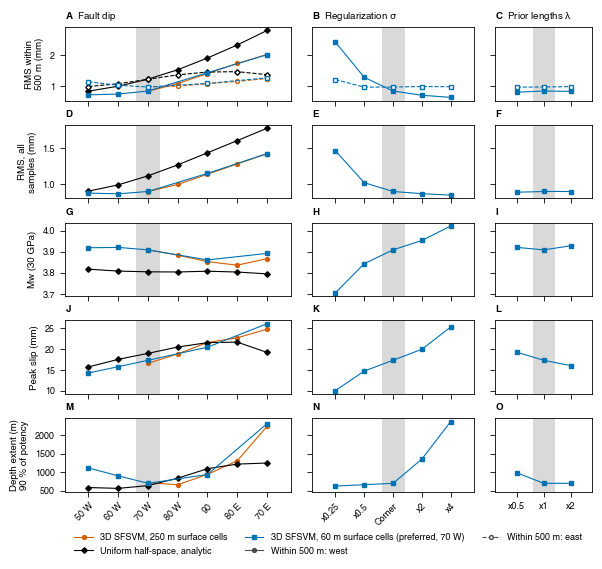

In [4]:
dips = tables["dip_rows.csv"]


def pick(row, variant):
    """Return the single row of the sensitivity table with this choice and variant.

    Parameters
    ----------
    row : str
        The choice (`row` column), e.g. "Prior lengths".
    variant : str
        The variant (`variant` column), e.g. "x2".

    Returns
    -------
    pandas.Series
        The row.
    """
    found = rows[(rows.row == row) & (rows.variant == variant)]
    assert len(found) == 1, f"{row} {variant}: {len(found)} rows"
    return found.iloc[0]


dip_series = []
for family, colour, marker, label in (("3D N^0", OKABE["vermillion"], "o", "3D SFSVM, 250 m surface cells"),
                                      ("Homogeneous analytic N^0", OKABE["black"], "D", "Uniform half-space, analytic")):
    series = dips[dips.family == family].copy()
    series["x"] = series.dip_from_vertical_deg
    dip_series.append((label, colour, marker, series.sort_values("x")))
dip_x = {"50 W": -40, "60 W": -30, "70 W": -20, "80 W": -10, "Vertical": 0, "80 E": 10, "70 E": 20}   # degrees from vertical, W < 0
fine_rows = rows[rows.row == "Fault dip, fine mesh"]
fine_dips = pd.concat([fine_rows, baseline.to_frame().T], ignore_index=True)
fine_dips["x"] = [dip_x[v] for v in fine_rows.variant] + [dip_x[cfg.selected_dip_label]]
assert fine_dips.x.is_unique, "two fine-mesh rows at the same dip"
fine_dips = fine_dips.sort_values("x")
selected_label = f"3D SFSVM, 60 m surface cells (preferred, {cfg.selected_dip_label})"
dip_series.append((selected_label, OKABE["blue"], "s", fine_dips))
sigma_labels = ["x0.25", "x0.5", "Corner", "x2", "x4"]
sigma_frame = pd.DataFrame([baseline if lab == "Corner" else pick("Regularization sigma", lab) for lab in sigma_labels])
sigma_frame["x"] = np.arange(len(sigma_labels))
lambda_labels = ["x0.5", "x1", "x2"]
lambda_frame = pd.DataFrame([baseline if lab == "x1" else pick("Prior lengths", lab) for lab in lambda_labels])
lambda_frame["x"] = np.arange(len(lambda_labels))
selected_series = (selected_label, OKABE["blue"], "s")
metrics = [("near", "RMS within\n500 m (mm)"), ("rms_mm", "RMS, all\nsamples (mm)"), ("Mw_30gpa", "Mw (30 GPa)"),
           ("peak_slip_mm", "Peak slip (mm)"), ("depth90_m", "Depth extent (m)\n90 % of potency")]
dip_ticks = [-40, -30, -20, -10, 0, 10, 20]
sweeps = [("Fault dip", dip_series, dip_ticks, ["50 W", "60 W", "70 W", "80 W", "90", "80 E", "70 E"], dip_ticks.index(dip_x[cfg.selected_dip_label])),
          ("Regularization $\\sigma$", [selected_series + (sigma_frame,)], list(range(5)), sigma_labels, 2),
          ("Prior lengths $\\lambda$", [selected_series + (lambda_frame,)], list(range(3)), lambda_labels, 1)]
lw, ms = 0.8, 2.8
fig = plt.figure(figsize=(15.0 * cm, 14.0 * cm), constrained_layout=True)
fig.get_layout_engine().set(h_pad=0.01, hspace=0.0)
grid = fig.add_gridspec(len(metrics) + 1, len(sweeps), height_ratios=[1] * len(metrics) + [0.10], width_ratios=[7, 5, 3])
axes = np.empty((len(metrics), len(sweeps)), dtype=object)
for j in range(len(sweeps)):
    for i in range(len(metrics)):
        axes[i, j] = fig.add_subplot(grid[i, j], sharex=axes[0, j] if i else None, sharey=axes[i, 0] if j else None)
legend_ax = fig.add_subplot(grid[len(metrics), :])
legend_ax.axis("off")
handles = {}
letters = "ABCDEFGHIJKLMNO"
for j, (name, series_list, ticks, tick_labels, selected_at) in enumerate(sweeps):
    for i, (metric, metric_label) in enumerate(metrics):
        ax = axes[i, j]
        half = 0.4 * (ticks[1] - ticks[0])
        ax.set_xlim(ticks[0] - 2 * half, ticks[-1] + 2 * half)
        ax.axvspan(ticks[selected_at] - half, ticks[selected_at] + half, color="0.85", lw=0, zorder=0)
        utils.panel_title(ax, letters[len(sweeps) * i + j], name if i == 0 else "")
        if j == 0:
            ax.set_ylabel(metric_label)
        else:
            plt.setp(ax.get_yticklabels(), visible=False)
        ax.set_xticks(ticks)
        if i == len(metrics) - 1:
            rotation = 45 if len(tick_labels) > 3 else 0
            ax.set_xticklabels(tick_labels, rotation=rotation, ha="right" if rotation else "center", rotation_mode="anchor")
        else:
            plt.setp(ax.get_xticklabels(), visible=False)
        for label, colour, marker, frame in series_list:
            if metric == "near":
                ax.plot(frame.x, frame.rms_west_mm, "-", marker=marker, color=colour, lw=lw, ms=ms)
                ax.plot(frame.x, frame.rms_east_mm, "--", marker=marker, color=colour, lw=lw, ms=ms, mfc="white")
            else:
                ax.plot(frame.x, frame[metric], "-", marker=marker, color=colour, lw=lw, ms=ms)
            handles.setdefault(label, Line2D([], [], color=colour, marker=marker, lw=lw, ms=ms, label=label))
handles["West"] = Line2D([], [], color="0.3", ls="-", marker="o", lw=lw, ms=ms, label="Within 500 m: west")
handles["East"] = Line2D([], [], color="0.3", ls="--", marker="o", mfc="white", lw=lw, ms=ms, label="Within 500 m: east")
legend_ax.legend(handles=list(handles.values()), loc="center", ncol=3, frameon=False)
save(fig, f"figS_sweeps_{cfg.selected_dip_tag}")

## 5. The fixed-depth scan (SM)

The fixed-depth scan (`scripts/sensitivity/depth_scan.py`) fits uniform slip from the surface to a depth $D$ over the
SSE section, tapered over 0.5 km at each end, with one amplitude and a plane, by least squares with equal weights:

$$\mathbf{d} \approx \bar{d}\,G\boldsymbol{\phi}_D + B\mathbf{a} ,$$

where $\mathbf{d}$ is the vector of fault-parallel samples (mm), $\bar{d}$ the uniform slip (mm), $G$ the Green's
functions of the preferred run (m/m), $\boldsymbol{\phi}_D$ the slip pattern (1 at the impulse vertices from the
surface to $D$ in the section, 0 elsewhere), $B$ the plane design matrix with rows $(1, x_i, y_i)$, and $\mathbf{a}$
the plane coefficients (notebook 09, section 12). The figure shows, against $D$, the RMS within 500 m west and east of
the trace, the RMS of all fitted samples, and the best-fit slip with its Mw at 30 GPa,
$M_w = \frac{2}{3}\left(\log_{10} M_0 - 9.1\right)$ (Hanks & Kanamori 1979). The dotted lines are the preferred
distributed-slip model. The grey band is the base of the Cenozoic sediment west of the fault in the SFSVM, within
500 m of the trace over the 90 % band (`scripts/sensitivity/basement_depth.py`; median as a line, range as the band).

Two tests are printed for the caption. In the noise test, the best uniform-slip model plus its plane is used as
synthetic data, 100 realisations of correlated noise from the full noise covariance (notebook 07, section 4) are
added, and each realisation is scanned in the same way; the spread of the best $D$ is reported. In the buried-top
test, the scan is repeated with no slip above 50, 100 and 200 m.

     metric  true_D_km  best_D_data_km  noise_p2_5  noise_p16  noise_median  noise_p84  noise_p97_5                                                                                                                       provenance
All samples       0.55            0.55        0.45        0.5          0.55       0.62         1.18 /Users/dlindsay/tools/internal/TulePond_DISP/scripts/sensitivity/depth_scan.py | depth_scan.py | git db65645+ | 2026-10-30 22:32
 West 500 m       0.55            0.70        0.45        0.5          0.55       0.60         0.60 /Users/dlindsay/tools/internal/TulePond_DISP/scripts/sensitivity/depth_scan.py | depth_scan.py | git db65645+ | 2026-10-30 22:32
 East 500 m       0.55            0.30        0.10        0.2          0.45       1.00         3.00 /Users/dlindsay/tools/internal/TulePond_DISP/scripts/sensitivity/depth_scan.py | depth_scan.py | git db65645+ | 2026-10-30 22:32
 top_km  best_D_km  slip_mm  rms_all_mm  rms_W500_mm  rms_E500_mm                   

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


1 extra bytes in post.stringData array


saved /Users/dlindsay/work/proj_TulePond_DISP_release/Figures_2026-11-03/figS_depth_scan_dip70w.png


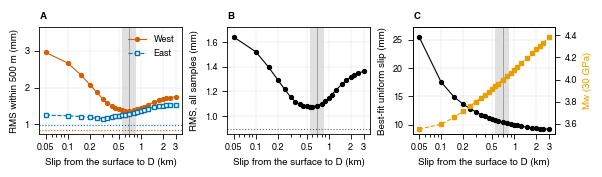

In [5]:
scan = tables["depth_scan.csv"]
noise_test = tables["depth_scan_noise.csv"]
buried_top = tables["depth_scan_buried_top.csv"]
basement = tables["basement_depth.csv"]
west_basement = basement[basement.km.between(band_lo_km, band_hi_km) & (basement.side == "west")].basement_top_m / 1e3
b_median, b_lo, b_hi = west_basement.median(), west_basement.min(), west_basement.max()
best = scan.loc[scan.rms_all_mm.idxmin()]
print(noise_test.round(2).to_string(index=False))
print(buried_top.round(3).to_string(index=False))
fig, axes = plt.subplots(1, 3, figsize=(15.0 * cm, 4.2 * cm), constrained_layout=True, sharex=True)
ax = axes[0]
ax.plot(scan.D_km, scan.rms_W500_mm, "o-", color=OKABE["vermillion"], lw=lw, ms=ms, label="West")
ax.plot(scan.D_km, scan.rms_E500_mm, "s--", color=OKABE["blue"], lw=lw, ms=ms, mfc="white", label="East")
ax.axhline(baseline.rms_west_mm, color=OKABE["vermillion"], ls=":", lw=lw)
ax.axhline(baseline.rms_east_mm, color=OKABE["blue"], ls=":", lw=lw)
ax.legend(loc="upper right", frameon=False)   # notes are in the caption, not on the panels
ax = axes[1]
ax.plot(scan.D_km, scan.rms_all_mm, "o-", color="k", lw=lw, ms=ms)
ax.axhline(baseline.rms_mm, color="0.4", ls=":", lw=lw)
ax = axes[2]
ax.plot(scan.D_km, scan.slip_mm, "o-", color="k", lw=lw, ms=ms)
twin = ax.twinx()
twin.plot(scan.D_km, scan.Mw_30gpa, "s--", color=OKABE["orange"], lw=lw, ms=ms)
twin.set_ylabel("Mw (30 GPa)", color=OKABE["orange"])
for ax, letter, ylabel in ((axes[0], "A", "RMS within 500 m (mm)"),
                           (axes[1], "B", "RMS, all samples (mm)"),
                           (axes[2], "C", "Best-fit uniform slip (mm)")):
    utils.panel_title(ax, letter, "")
    ax.set_ylabel(ylabel)
    ax.set_xlabel("Slip from the surface to D (km)")
    ax.axvspan(b_lo, b_hi, color="0.88", lw=0, zorder=0)
    ax.axvline(b_median, color="0.5", lw=lw * 0.6, zorder=0)
    ax.set_xscale("log")
    ax.set_xticks([0.05, 0.1, 0.2, 0.5, 1, 2, 3])
    ax.set_xticklabels(["0.05", "0.1", "0.2", "0.5", "1", "2", "3"])
    ax.grid(True, lw=0.3, color="0.85")
print(f"caption: grey band = base of the Cenozoic sediment west of the fault (SFSVM), {1e3 * b_median:.0f} m "
      f"({1e3 * b_lo:.0f}-{1e3 * b_hi:.0f} m); dotted = the preferred distributed-slip model")
for axis, fraction in ((axes[0], 0.25), (axes[1], 0.05), (axes[2], 0.05), (twin, 0.05)):
    lo, hi = axis.get_ylim()
    axis.set_ylim(lo, hi + fraction * (hi - lo))
save(fig, f"figS_depth_scan_{cfg.selected_dip_tag}")

## 6. The Green's functions against the analytic solution (SM)

For each impulse $j$, the homogeneous PyLith Green's function is compared with the analytic solution for the same tent
(`scripts/sensitivity/gf_check.py`; CSI triangular dislocations, Meade 2007, with $n_{sub} = 8$ as in notebook 08,
section 3):

$$\epsilon_j = \frac{\lVert \mathbf{g}^{PyLith}_j - \mathbf{g}^{analytic}_j \rVert_2}{\lVert \mathbf{g}^{analytic}_j \rVert_2} ,$$

where $\mathbf{g}_j$ is the fault-parallel displacement at the samples for unit slip on tent $j$ (m/m) and the norms
run over the samples. The figure shows $100\,\epsilon_j$ (%). Panel A compares element order 1 and 2 on the default
mesh. Panel B compares the three meshes at order 2 in the strip km 58.85 to 59.25; the mesh of the preferred model
(60 m cells within 1 km of the fault) is in blue.

impulses whose PyLith sign disagrees with the analytic solution: 1
panel              run  impulse       km   depth_m  rel_rms
    A gf_default_homog     1030 60.23463 86.655462 1.272271
depth_group                          1-100 m  100-200 m  200-400 m  400-2000 m  Surface
panel run                                                                              
A     gf_default_homog                  93.0        NaN       44.2        15.1     67.8
      gf_default_homog_order2           31.7        NaN        2.9         0.3     19.1
B     gf_default_homog_order2           17.1        7.3        4.4         0.5     16.9
      gf_fine_homog_order2_strip         8.9        3.1        1.0         0.2     10.5
      gf_shallow_homog_order2_strip      6.8        2.2        0.7         0.3     12.8


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


1 extra bytes in post.stringData array


saved /Users/dlindsay/work/proj_TulePond_DISP_release/Figures_2026-11-03/figS_gf_error_vs_depth.png


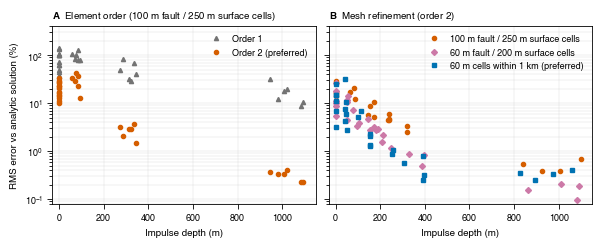

In [6]:
gf = tables["gf_check.csv"]
# a PyLith impulse whose sign disagrees with the analytic solution (whose sign is fixed and tested) is drawn and listed,
# not flipped; only order-1 runs may have one (asserted)
disagree = gf[~gf.sign_agrees]
print(f"impulses whose PyLith sign disagrees with the analytic solution: {len(disagree)}")
print(disagree[["panel", "run", "impulse", "km", "depth_m", "rel_rms"]].to_string(index=False))
assert (disagree.order == 1).all(), "an order-2 PyLith impulse disagrees in sign with the analytic solution"
fig, axes = plt.subplots(1, 2, figsize=(15.0 * cm, 6.0 * cm), constrained_layout=True, sharey=True)
panel_a = gf[gf.panel == "A"]
for run, colour, marker, label in (("gf_default_homog", "0.45", "^", "Order 1"), ("gf_default_homog_order2", OKABE["vermillion"], "o", "Order 2 (preferred)")):
    part = panel_a[panel_a.run == run]
    axes[0].plot(part.depth_m, 100 * part.rel_rms, ls="none", marker=marker, color=colour, ms=3.0, label=label)
panel_b = gf[gf.panel == "B"]
for run, colour, marker, label in (("gf_default_homog_order2", OKABE["vermillion"], "o", "100 m fault / 250 m surface cells"),
                                   ("gf_fine_homog_order2_strip", OKABE["purple"], "D", "60 m fault / 200 m surface cells"),
                                   ("gf_shallow_homog_order2_strip", OKABE["blue"], "s", "60 m cells within 1 km (preferred)")):
    part = panel_b[panel_b.run == run]
    axes[1].plot(part.depth_m, 100 * part.rel_rms, ls="none", marker=marker, color=colour, ms=3.0, label=label)
for ax, letter, title in ((axes[0], "A", "Element order (100 m fault / 250 m surface cells)"), (axes[1], "B", "Mesh refinement (order 2)")):
    ax.set_yscale("log")
    ax.set_ylim(0.08, 400)
    ax.set_xlim(-30, 1150)
    ax.set_xlabel("Impulse depth (m)")
    ax.grid(True, which="both", lw=0.3, color="0.85")
    ax.legend(loc="upper right", frameon=False)
    utils.panel_title(ax, letter, title)
axes[0].set_ylabel("RMS error vs analytic solution (%)")
gf_medians = gf.groupby(["panel", "run", "depth_group"], observed=True).rel_rms.median().unstack() * 100
print(gf_medians.round(1).to_string())
save(fig, "figS_gf_error_vs_depth")

## 7. The noise model: semivariogram of the far field (Methods, SM)

The figure shows the products of notebook 07, section 4: the binned semivariogram of the pixels farther than 5 km
from the trace (plane removed) and the fitted model (`model_utils.semivariogram_model`; Lohman & Simons 2005; Sudhaus
& Jónsson 2009),

$$\gamma(h) = n^2 + s_1\left(1 - e^{-h/l_1}\right) + s_2\left(1 - e^{-h/l_2}\right) ,$$

where $h$ is the distance between two pixels (km), $\gamma$ the semivariance (mm$^2$), $n^2$ the nugget (mm$^2$),
$s_1$ and $s_2$ the sills of a short- and a long-range exponential term (mm$^2$), and $l_1$ and $l_2$ their ranges
(km). The dotted line is the nugget.

23,913 pixels beyond 5 km; nugget 0.903 mm; exponential 0.893 mm / 1.70 km; total sd 1.270 mm


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


saved /Users/dlindsay/work/proj_TulePond_DISP_release/Figures_2026-11-03/figS_semivariogram.png


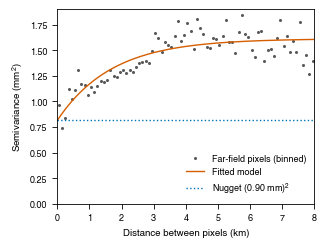

In [7]:
noise = pd.read_csv(noise_file).iloc[0]
semivariogram = pd.read_csv(bins_file)
params = (noise.nugget2_mm2, noise.sill_short_mm2, noise.range_short_km, noise.sill_long_mm2, noise.range_long_km)
fitted = semivariogram.gamma_mm2.notna()
fig, ax = plt.subplots(figsize=(8.0 * cm, 6.0 * cm), constrained_layout=True)
ax.plot(semivariogram.distance_km[fitted], semivariogram.gamma_mm2[fitted], "o", color="0.35", ms=2.2, mec="none",
        label="Far-field pixels (binned)")
distance = np.linspace(0, noise.distmax_km, 400)
ax.plot(distance, model_utils.semivariogram_model(distance, *params), "-", color=OKABE["vermillion"], lw=1.0, label="Fitted model")
ax.axhline(noise.nugget2_mm2, color=OKABE["blue"], ls=":", lw=1.0, label=f"Nugget ({noise.nugget_mm:.2f} mm)$^2$")
ax.set_xlim(0, noise.distmax_km)
ax.set_ylim(0, None)
ax.set_xlabel("Distance between pixels (km)")
ax.set_ylabel("Semivariance (mm$^2$)")
ax.legend(loc="lower right", frameon=False)
print(f"{int(noise.n_pixels):,} pixels beyond {noise.mask_km:g} km; nugget {noise.nugget_mm:.3f} mm; exponential "
      f"{noise.short_sd_mm:.3f} mm / {noise.range_short_km:.2f} km; total sd {noise.total_sd_mm:.3f} mm")
save(fig, "figS_semivariogram")

## 8. Fault-normal motion and the asymmetry of the near-fault deflection (SM)

The ascending and descending tracks give two numbers per place, so the decomposition solves for two unknowns. The
paper's choice is fault-parallel (FP) and vertical (U), assuming no fault-normal (FN) motion (Methods M2, M7). At this
geometry FN motion is returned as FP with a gain of about 1.5 (`leak_gain`), so the assumption matters for the
asymmetry of the near-fault deflections. `scripts/sensitivity/fault_normal_leak.py` takes the near-fault LOS
deflection of each track on each side of the trace in the SSE section (the M7 definition: the mean over 0.06 to 0.25 km
from the trace minus the mean over 1.5 to 3 km) and solves it twice, as (FP, U) and as (FP, FN). The (FP, U) solution
reproduces the deflection of 06's fault-parallel field (asserted in the script). The 5 to 95 % ranges come from a
bootstrap over 0.5 km along-strike bins. The figure shows both solutions along strike, per 0.5 km bin.

**Forward test** (`scripts/sensitivity/forward_decomposition_check.py`). The full 3D surface displacement of the
preferred model (09) at the inversion samples is projected into both lines of sight and decomposed with no
fault-normal motion, as the data are. If the apparent fault-parallel deflections equal the model's true ones, the
geometry and the decomposition do not make the asymmetry from the model's own vertical and fault-normal motion. The
script asserts that the 3D displacements reproduce the run's G and that G times the slip reproduces 09's prediction.

              assumption      side  fp_mm  fp_q05  fp_q95 second  second_mm  second_q05  second_q95  los_asc_mm  los_desc_mm  fp_direct_mm  leak_gain
FP+U (FN = 0, the paper)      west  -4.91   -5.85   -3.89      U       0.59        0.34        0.90        1.73        -1.87         -4.90        1.5
FP+U (FN = 0, the paper)      east   2.15    1.50    2.73      U       0.32        0.07        0.62       -0.32         1.24          2.15        1.5
FP+U (FN = 0, the paper) west/east   2.28    1.79    3.13      U        NaN         NaN         NaN         NaN          NaN           NaN        NaN
           FP+FN (U = 0)      west  -1.69   -3.17    0.16     FN      -2.15       -3.26       -1.24        1.73        -1.87         -4.90        1.5
           FP+FN (U = 0)      east   3.91    2.39    5.38     FN      -1.18       -2.28       -0.24       -0.32         1.24          2.15        1.5
           FP+FN (U = 0) west/east   0.43    0.05    0.98     FN        NaN         NaN         NaN 

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


Saved figure to: /Users/dlindsay/work/proj_TulePond_DISP_release/Figures_2026-11-03/figS_fault_normal_leak.png


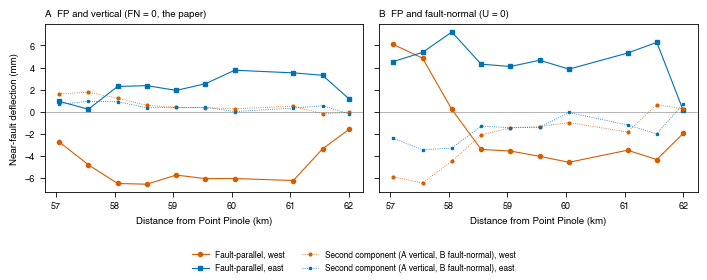

In [8]:
leak = tables["fault_normal_leak.csv"]
leak_bins = tables["fault_normal_leak_bins.csv"]
forward = tables["forward_decomposition_check.csv"].set_index("field")
paper = "FP+U (FN = 0, the paper)"
alternative = "FP+FN (U = 0)"


def leak_value(assumption, side, column="fp_mm"):
    """One number of fault_normal_leak.csv.

    Parameters
    ----------
    assumption : str
        The decomposition (`paper` or `alternative`).
    side : str
        'west', 'east' or 'west/east'.
    column : str

    Returns
    -------
    float
    """
    row = leak[(leak.assumption == assumption) & (leak.side == side)]
    assert len(row) == 1, f"no single row for {assumption} {side}"
    return float(row[column].iloc[0])


print(leak.drop(columns="provenance").round(2).to_string(index=False))
print(f"forward test, {forward.run.iloc[0]}:")
print(forward.drop(columns=["provenance", "run"]).round(3).to_string())
fig, axes = plt.subplots(1, 2, figsize=(18 * cm, 7 * cm), sharey=True)
centre_km = 0.5 * (leak_bins.km_lo + leak_bins.km_hi)
for ax, (tag, title) in zip(axes, (("fpu", "A  FP and vertical (FN = 0, the paper)"), ("fpfn", "B  FP and fault-normal (U = 0)"))):
    ax.axhline(0, color="0.6", lw=0.5)
    ax.plot(centre_km, leak_bins[f"{tag}_fp_west_mm"], "o-", color=OKABE["vermillion"], ms=3, lw=0.8, label="Fault-parallel, west")
    ax.plot(centre_km, leak_bins[f"{tag}_fp_east_mm"], "s-", color=OKABE["blue"], ms=3, lw=0.8, label="Fault-parallel, east")
    second = "u" if tag == "fpu" else "fn"
    ax.plot(centre_km, leak_bins[f"{tag}_{second}_west_mm"], "o:", color=OKABE["vermillion"], ms=2, lw=0.6,
            label="Second component (A vertical, B fault-normal), west")
    ax.plot(centre_km, leak_bins[f"{tag}_{second}_east_mm"], "s:", color=OKABE["blue"], ms=2, lw=0.6,
            label="Second component (A vertical, B fault-normal), east")
    ax.set_xlabel("Distance from Point Pinole (km)")
    ax.set_title(title, fontsize=7, loc="left")
axes[0].set_ylabel("Near-fault deflection (mm)")
handles, labels = axes[0].get_legend_handles_labels()       # one legend under both panels, clear of the data
fig.legend(handles, labels, loc="lower center", ncol=2, fontsize=6, frameon=False)
fig.tight_layout(rect=(0, 0.14, 1, 1))
f_leak = os.path.join(fig_dir, "figS_fault_normal_leak.png")
fig.savefig(f_leak, dpi=300)
fig.savefig(f_leak.replace(".png", ".pdf"))
print("Saved figure to:", f_leak)
plt.show()

## 9. Registry

The numbers quoted in the supplementary material are registered with a stats file of the csv provenance and the
printed tables.

In [9]:
stats = REG.sidecar("10_model_sensitivity", [f"{name}: {sorted(set(table.provenance))[0]}" for name, table in tables.items()]
                    + [sensitivity_table.to_string(index=False), noise_test.to_string(index=False), buried_top.to_string(index=False),
                       gf_medians.to_string(), leak.drop(columns="provenance").to_string(index=False)])
where = "SM"
for assumption, tag in ((paper, "fpu"), (alternative, "fpfn")):
    for side in ("west", "east"):
        REG.register(f"10_fnleak_{tag}_fp_{side}_mm", leak_value(assumption, side), "mm", 1, where, "section 8", stats)
        REG.register(f"10_fnleak_{tag}_second_{side}_mm", leak_value(assumption, side, "second_mm"), "mm", 1, where, "section 8", stats)
    REG.register(f"10_fnleak_{tag}_ratio_we", leak_value(assumption, "west/east"), "1", 2, where, "section 8", stats)
    REG.register(f"10_fnleak_{tag}_ratio_we_q05", leak_value(assumption, "west/east", "fp_q05"), "1", 2, where, "section 8", stats)
    REG.register(f"10_fnleak_{tag}_ratio_we_q95", leak_value(assumption, "west/east", "fp_q95"), "1", 2, where, "section 8", stats)
for field, tag in (("model fault-parallel (true)", "true"), ("apparent fault-parallel (decomposed, FN = 0)", "apparent"),
                   ("model fault-normal", "model_fn"), ("model vertical", "model_u")):
    for side in ("west", "east"):
        REG.register(f"10_forward_{tag}_{side}_mm", float(forward.loc[field, f"{side}_mm"]), "mm", 2, where, "section 8", stats)
REG.register("10_fnleak_gain", leak_value(paper, "west", "leak_gain"), "1", 2, where, "section 8", stats)
REG.register("10_mw_range_lo", mw_range[0], "Mw", 2, where, "section 3", stats)
REG.register("10_mw_range_hi", mw_range[1], "Mw", 2, where, "section 3", stats)
REG.register("10_mw_sigma_sweep_lo", sigma_rows.Mw_30gpa.min(), "Mw", 2, where, "section 3", stats)
REG.register("10_mw_sigma_sweep_hi", sigma_rows.Mw_30gpa.max(), "Mw", 2, where, "section 3", stats)
REG.register("10_depth90_sigma_lo_m", min(sigma_rows.depth90_m.min(), baseline.depth90_m), "m", 0, where, "section 3", stats)
REG.register("10_depth90_sigma_hi_m", max(sigma_rows.depth90_m.max(), baseline.depth90_m), "m", 0, where, "section 3", stats)
REG.register("10_depth90_lambda_lo_m", rows[rows.row == "Prior lengths"].depth90_m.min(), "m", 0, where, "section 3", stats)
REG.register("10_depth90_lambda_hi_m", rows[rows.row == "Prior lengths"].depth90_m.max(), "m", 0, where, "section 3", stats)
REG.register("10_full_cd_mw_30gpa", pick("Data weighting", "Full Cd").Mw_30gpa, "Mw", 2, where, "section 3", stats)
REG.register("10_cut30_mw_30gpa", pick("Near-trace exclusion", "30 m").Mw_30gpa, "Mw", 2, where, "section 3", stats)
REG.register("10_depth_scan_best_d_m", 1e3 * best.D_km, "m", 0, where, "section 5", stats)
REG.register("10_depth_scan_best_slip_mm", best.slip_mm, "mm", 1, where, "section 5", stats)
all_samples = noise_test[noise_test.metric == "All samples"].iloc[0]
REG.register("10_depth_scan_noise_p16_m", 1e3 * all_samples.noise_p16, "m", 0, where, "section 5", stats)
REG.register("10_depth_scan_noise_p84_m", 1e3 * all_samples.noise_p84, "m", 0, where, "section 5", stats)
REG.register("10_depth_scan_noise_p97_5_m", 1e3 * all_samples.noise_p97_5, "m", 0, where, "section 5", stats)
REG.register("10_basement_west_band_median_m", 1e3 * b_median, "m", 0, where, "section 5", stats)
REG.render()

Saved stats to: /Users/dlindsay/work/proj_TulePond_DISP_release/outputs/10_model_sensitivity/10_model_sensitivity_stats.txt
  registered 10_fnleak_fpu_fp_west_mm = -4.9 mm  -> SM
  registered 10_fnleak_fpu_second_west_mm = 0.6 mm  -> SM
  registered 10_fnleak_fpu_fp_east_mm = 2.1 mm  -> SM


  registered 10_fnleak_fpu_second_east_mm = 0.3 mm  -> SM
  registered 10_fnleak_fpu_ratio_we = 2.28 1  -> SM
  registered 10_fnleak_fpu_ratio_we_q05 = 1.79 1  -> SM
  registered 10_fnleak_fpu_ratio_we_q95 = 3.13 1  -> SM
  registered 10_fnleak_fpfn_fp_west_mm = -1.7 mm  -> SM
  registered 10_fnleak_fpfn_second_west_mm = -2.1 mm  -> SM
  registered 10_fnleak_fpfn_fp_east_mm = 3.9 mm  -> SM
  registered 10_fnleak_fpfn_second_east_mm = -1.2 mm  -> SM


  registered 10_fnleak_fpfn_ratio_we = 0.43 1  -> SM
  registered 10_fnleak_fpfn_ratio_we_q05 = 0.05 1  -> SM
  registered 10_fnleak_fpfn_ratio_we_q95 = 0.98 1  -> SM
  registered 10_forward_true_west_mm = -5.34 mm  -> SM


  registered 10_forward_true_east_mm = 1.37 mm  -> SM
  registered 10_forward_apparent_west_mm = -4.98 mm  -> SM
  registered 10_forward_apparent_east_mm = 1.32 mm  -> SM
  registered 10_forward_model_fn_west_mm = 0.24 mm  -> SM


  registered 10_forward_model_fn_east_mm = -0.03 mm  -> SM
  registered 10_forward_model_u_west_mm = -0.09 mm  -> SM
  registered 10_forward_model_u_east_mm = -0.02 mm  -> SM
  registered 10_fnleak_gain = 1.50 1  -> SM
  registered 10_mw_range_lo = 3.80 Mw  -> SM
  registered 10_mw_range_hi = 3.93 Mw  -> SM
  registered 10_mw_sigma_sweep_lo = 3.70 Mw  -> SM
  registered 10_mw_sigma_sweep_hi = 4.02 Mw  -> SM


  registered 10_depth90_sigma_lo_m = 621 m  -> SM
  registered 10_depth90_sigma_hi_m = 2365 m  -> SM
  registered 10_depth90_lambda_lo_m = 695 m  -> SM
  registered 10_depth90_lambda_hi_m = 978 m  -> SM


  registered 10_full_cd_mw_30gpa = 3.86 Mw  -> SM
  registered 10_cut30_mw_30gpa = 3.90 Mw  -> SM
  registered 10_depth_scan_best_d_m = 550 m  -> SM
  registered 10_depth_scan_best_slip_mm = 10.8 mm  -> SM


  registered 10_depth_scan_noise_p16_m = 500 m  -> SM
  registered 10_depth_scan_noise_p84_m = 616 m  -> SM
  registered 10_depth_scan_noise_p97_5_m = 1179 m  -> SM
  registered 10_basement_west_band_median_m = 700 m  -> SM
Wrote the numbers to: /Users/dlindsay/work/proj_TulePond_DISP_release/outputs/paper_numbers.md


'/Users/dlindsay/work/proj_TulePond_DISP_release/outputs/paper_numbers.md'